In [1]:
import os
import re
import json
import glob
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

INPUT = "/kaggle/input/datasets/nocturnalnerd18"
OUT_DIR = "/kaggle/working/circuit_analysis"
os.makedirs(OUT_DIR, exist_ok=True)
SRC = f"{INPUT}/patch-llava-circuit"
TARGET = 0.8
with open(f"{SRC}/circuit_meta.json") as f:
    cmeta = json.load(f)
STEP_NAMES = cmeta["step_names"]
GROW_STEPS = cmeta["grow_steps"]
RANDOM_STEPS = cmeta["random_steps"]
CORE = {n: None for n in cmeta["core_names"]}
n_comp = [len(CORE) + (0 if n == "core" else int(n.split("+")[1])) for n in STEP_NAMES]


def batch_number(path):
    return int(re.search(r"_batch_(\d+)\.pt$", path).group(1))


def step_components(name):
    return [None] * (len(CORE) + (0 if name == "core" else int(name.split("+")[1])))

300 entries, 300 ok
3 questions with a non-finite value in some step are excluded (fp16 overflow in a mixed run)
--- driven false_yes: share of the clean to corrupt change, ratio of sums over questions, 95% interval over questions ---
            components              knockout                  only              restored                  rest
core                15  +0.19 [+0.14, +0.25]  +0.00 [-0.00, +0.00]  +0.25 [+0.20, +0.30]  +1.08 [+1.07, +1.09]
rank+8              23  +0.62 [+0.59, +0.66]  +0.01 [+0.00, +0.01]  +0.31 [+0.26, +0.37]  +1.05 [+1.05, +1.06]
rank+16             31  +0.90 [+0.87, +0.93]  +0.01 [+0.01, +0.01]  +0.24 [+0.19, +0.29]  +1.04 [+1.03, +1.05]
rank+32             47  +0.96 [+0.92, +0.99]  -0.01 [-0.01, -0.01]  +0.54 [+0.50, +0.57]  +1.00 [+0.99, +1.01]
rank+64             79  +0.70 [+0.66, +0.73]  -0.02 [-0.02, -0.01]  +0.53 [+0.50, +0.57]  +0.94 [+0.92, +0.97]
rank+128           143  +0.75 [+0.72, +0.79]  +0.00 [-0.01, +0.01]  +0.50 [+0.46, +0.54]  +0.69 [+0

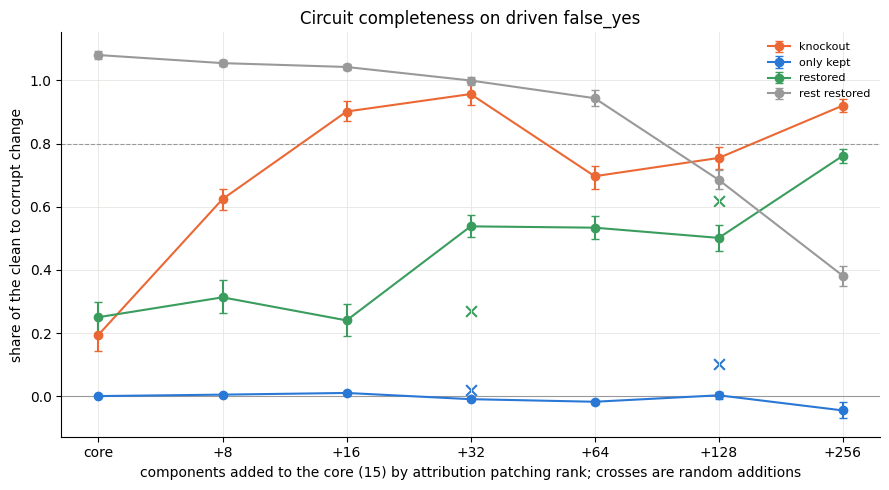

In [2]:
entries = []
for path in sorted(glob.glob(f"{SRC}/C_batch_*.pt"), key=batch_number):
    entries.extend(torch.load(path))
good = [e for e in entries if e["ok"]]
assert len({e["question_id"] for e in good}) == len(good), "duplicated entries"
print(f"{len(entries)} entries, {len(good)} ok")
finite = [bool(np.isfinite(e["curve"].numpy()).all()) for e in good]
print(f"{len(good) - sum(finite)} questions with a non-finite value in some step are excluded (fp16 overflow in a mixed run)")
good = [e for e, ok_ in zip(good, finite) if ok_]

CV = np.stack([e["curve"].numpy() for e in good]).astype(np.float64)
dc = np.array([e["delta_clean"] for e in good])
dk = np.array([e["delta_corrupt"] for e in good])
sign = np.array([e["sign"] for e in good])
role = np.array([e["stratum"] for e in good])
split = np.array([e["split"] for e in good])
uid = np.array([e["uid"] for e in good])
fy = np.flatnonzero(role == "false_yes")
ct = np.flatnonzero(role == "true_yes")
S = len(STEP_NAMES)
boot_rng = np.random.default_rng(1)


def share_sums(ix):
    den = (dk[ix] - dc[ix]).sum()
    knock = (CV[ix, :, 0] - dc[ix, None]).sum(0) / den
    only = 1 - (CV[ix, :, 1] - dc[ix, None]).sum(0) / den
    restored = (CV[ix, :, 2] - dk[ix, None]).sum(0) / -den
    rest = (CV[ix, :, 3] - dk[ix, None]).sum(0) / -den
    return np.stack([knock, only, restored, rest], 1)


def share_ci(ix, nb=1000):
    point = share_sums(ix)
    draws = boot_rng.integers(0, len(ix), size=(nb, len(ix)))
    boots = np.stack([share_sums(ix[d]) for d in draws])
    return point, np.percentile(boots, 2.5, axis=0), np.percentile(boots, 97.5, axis=0)


NAMES4 = ["knockout (share of TE removed)", "circuit only (share of clean behavior kept)", "restored (share of TE recovered)", "rest restored (share recovered without the circuit)"]
print("--- driven false_yes: share of the clean to corrupt change, ratio of sums over questions, 95% interval over questions ---")
point, lo, hi = share_ci(fy)
table = pd.DataFrame({"components": n_comp}, index=STEP_NAMES)
for j, nm in enumerate(["knockout", "only", "restored", "rest"]):
    table[nm] = [f"{point[i, j]:+.2f} [{lo[i, j]:+.2f}, {hi[i, j]:+.2f}]" for i in range(S)]
print(table.to_string())
print("knockout = clean input with the circuit knocked out; only = clean input with everything outside the circuit knocked out (share kept = 1 minus the removed share);")
print("restored = corrupt input with the circuit restored to clean; rest = corrupt input with everything outside the circuit restored to clean")

core_i = STEP_NAMES.index("core")
print("--- core circuit by split ---")
for nm, mask_ in [("train+val", np.isin(split, ["train", "val"])), ("test", split == "test")]:
    ix = np.flatnonzero((role == "false_yes") & mask_)
    if len(ix) >= 5:
        pt = share_sums(ix)[core_i]
        print(f"{nm:10s} n {len(ix):4d} | knockout {pt[0]:+.2f} | only kept {pt[1]:+.2f} | restored {pt[2]:+.2f} | rest restored {pt[3]:+.2f}")
    else:
        print(f"{nm:10s} n {len(ix)}: too few questions")

pairs = sorted(set(uid[fy]) & set(uid[ct]))
fy_ix = {u: i for u, i in zip(uid[fy], fy)}
ct_ix = {u: i for u, i in zip(uid[ct], ct)}
a_ix = np.array([fy_ix[u] for u in pairs])
b_ix = np.array([ct_ix[u] for u in pairs])
boot = boot_rng.integers(0, len(pairs), size=(1000, len(pairs)))
print(f"--- specificity: false_yes minus matched true_yes support for Yes over {len(pairs)} units, mean [95% interval], logits ---")
sup_ko = -sign[:, None] * (CV[:, :, 0] - dc[:, None])
sup_re = sign[:, None] * (CV[:, :, 2] - dk[:, None])
for nm, arr in [("knockout (noising the circuit)", sup_ko), ("restored (denoising the circuit)", sup_re)]:
    diff = arr[a_ix] - arr[b_ix]
    means = diff[boot].mean(1)
    for i in [core_i, STEP_NAMES.index(f"rank+{GROW_STEPS[-1]}")]:
        print(f"{nm:34s} {STEP_NAMES[i]:10s} {diff.mean(0)[i]:+.3f} [{np.percentile(means[:, i], 2.5):+.3f}, {np.percentile(means[:, i], 97.5):+.3f}]")

print("--- growth: ranked additions against random additions (point estimates) ---")
for k in RANDOM_STEPS:
    if k in GROW_STEPS:
        r_, q_ = STEP_NAMES.index(f"rank+{k}"), STEP_NAMES.index(f"random+{k}")
        print(f"+{k:3d} components: ranked only kept {point[r_, 1]:+.2f} restored {point[r_, 2]:+.2f} | random only kept {point[q_, 1]:+.2f} restored {point[q_, 2]:+.2f}")
reached = [(STEP_NAMES[i], n_comp[i]) for i in range(1 + len(GROW_STEPS)) if point[i, 1] >= TARGET and point[i, 2] >= TARGET]
core_ok = point[core_i, 1] >= TARGET and point[core_i, 2] >= TARGET
print(f"verdict: core circuit keeps {point[core_i, 1]:.2f} of the clean behavior and restores {point[core_i, 2]:.2f} of the effect;",
      "it is faithful at the target level." if core_ok else f"it is not faithful at the {TARGET} target.")
print("first step reaching the target on both:", reached[0] if reached else f"none up to rank+{GROW_STEPS[-1]} ({n_comp[len(GROW_STEPS)]} components)")

BLUE, ORANGE, GREY, GREEN = "#2a78d6", "#eb6834", "#999999", "#3a9d5d"
fig, ax = plt.subplots(figsize=(9, 5))
xs = np.arange(1 + len(GROW_STEPS))
for j, (nm, color) in enumerate([("knockout", ORANGE), ("only kept", BLUE), ("restored", GREEN), ("rest restored", GREY)]):
    ax.errorbar(xs, point[:1 + len(GROW_STEPS), j], yerr=[point[:1 + len(GROW_STEPS), j] - lo[:1 + len(GROW_STEPS), j], hi[:1 + len(GROW_STEPS), j] - point[:1 + len(GROW_STEPS), j]],
                color=color, marker="o", capsize=3, label=nm)
for k in RANDOM_STEPS:
    if k in GROW_STEPS:
        x_ = 1 + GROW_STEPS.index(k)
        ax.scatter([x_], [point[STEP_NAMES.index(f"random+{k}"), 1]], marker="x", color=BLUE, s=60)
        ax.scatter([x_], [point[STEP_NAMES.index(f"random+{k}"), 2]], marker="x", color=GREEN, s=60)
ax.set_xticks(xs)
ax.set_xticklabels(["core"] + [f"+{k}" for k in GROW_STEPS])
ax.axhline(TARGET, color=GREY, lw=0.8, ls="--")
ax.axhline(0, color=GREY, lw=0.8)
ax.set_xlabel(f"components added to the core ({len(CORE)}) by attribution patching rank; crosses are random additions")
ax.set_ylabel("share of the clean to corrupt change")
ax.set_title("Circuit completeness on driven false_yes")
ax.grid(color="#e5e5e2", lw=0.6)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "circuit_growth.png"), dpi=150)
plt.show()

with open(os.path.join(OUT_DIR, "circuit_summary.json"), "w") as f:
    json.dump({
        "n_ok": len(good), "n_false_yes": int(len(fy)), "n_pairs": len(pairs), "step_names": STEP_NAMES, "n_components": n_comp,
        "shares": point.tolist(), "ci_lo": lo.tolist(), "ci_hi": hi.tolist(), "config_order": ["knockout", "only_kept", "restored", "rest_restored"],
        "core_names": list(CORE), "target": TARGET, "n_excluded_nonfinite": int(len(finite) - sum(finite)),
    }, f)